# 6. Ordinary Differential Equations: Exercise

Name: Xiuning Zhang

Date: 2026.11.9

In [2]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
from scipy.integrate import odeint

## 1. Linear ODEs
Like the exponential of a real number $x$ is given by

$$ e^{x} = 1 + x + \frac{1}{2} x^2 + \frac{1}{6} x^3 + ...
  = \sum_{k=0}^{\infty} \frac{1}{k!} x^k, $$

the *exponential of a matrix* $X$ is defined as

$$ e^{X} = I + X + \frac{1}{2} X^2 + \frac{1}{6} X^3 + ...
  = \sum_{k=0}^{\infty} \frac{1}{k!} X^k. $$

For one dimensional linear ODE

$$ \frac{dy}{dt} = a y $$

the solution is given by

$$ y(t) = e^{at} y(0), $$

where $y(0)$ is the initial state.

For an $n$ dimensional linear ODE

$$ \frac{dy}{dt} = A y $$

where $A$ is an $n\times n$ matrix, the solution is given by the matrix exponential

$$ y(t) = e^{At} y(0), $$

where $y(0)$ is an $n$-dimensional initial state.

* Verify this by expanding $e^{At}$ accordint to the definition and differentiating each term by $t$.

In [3]:
from scipy.linalg import expm
A = np.array([[-1.0, 2.0], [-2.0, -1.0]])
t, h = 0.7, 1e-6
dexp = (expm(A * (t + h)) - expm(A * (t - h))) / (2 * h)   # d/dt e^{At}
print(np.allclose(dexp, A @ expm(A * t)))                   # True: equals A e^{At}

True


**Suggested answer:** Expand $e^{At} = I + At + (At)^2/2! + (At)^3/3! + ...$ and differentiate each term by t: $d/dt e^{At} = A + A^2 t + A^3 t^2/2! + ... = A (I + At + (At)^2/2! + ...) = A e^{At}$. So $y(t) = e^{At} y(0)$ gives $dy/dt = A e^{At}$ $y(0) = A y(t)$, with $y(t) = y(0)$ at t = 0. The code checks this numerically with scipy's expm.

The behavior of the matrix exponentioal $e^{At}$ depends on the eivenvalues of $A$; whether the eigenvalues are real or complex, and whether the real part is positive or negative.

Let us visualize solutions for different eigenvalues.

In [2]:
def linear(y, t, A):
    """Linear dynamcal system dy/dt = Ay
    y: n-dimensional state vector
    t: time (not used, for compatibility with odeint())
    A: n*n matrix"""
    # y is an array (row vector), A is a matrix
    return A@y

In [3]:
def linear2D(A, yinit=np.array([[1,0],[0,1],[-1,0],[0,-1]]), t=np.arange(0, 5, 0.1)):
    """Visualizing linear 2D dynamical system"""
    for y0 in yinit:
        y = odeint(linear, y0, t, args=(A,))
        plt.plot(y[0,0], y[0,1], 'o')   # starting point
        plt.plot(y[:,0], y[:,1], '+-')  # trajectory
    plt.axis('equal')
    return np.linalg.eig(A)

1) Real eigenvalues $\lambda_1 > \lambda_2 > 0$

EigResult(eigenvalues=array([2.+0.j, 1.+0.j]), eigenvectors=array([[1.+0.j, 0.+0.j],
       [0.+0.j, 1.+0.j]]))

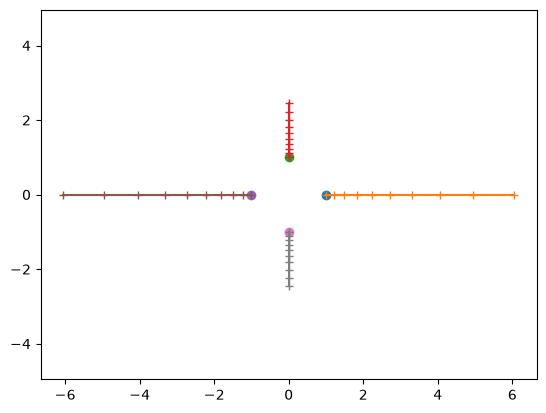

In [4]:
A = np.array([[2, 0], [0, 1]])  # modify this!
linear2D(A, t=np.arange(0, 1, 0.1))

2) Real eigenvalues $\lambda_1 > 0 > \lambda_2$

EigResult(eigenvalues=array([ 2.+0.j, -1.+0.j]), eigenvectors=array([[ 1.        +0.j, -0.31622777+0.j],
       [ 0.        +0.j,  0.9486833 +0.j]]))

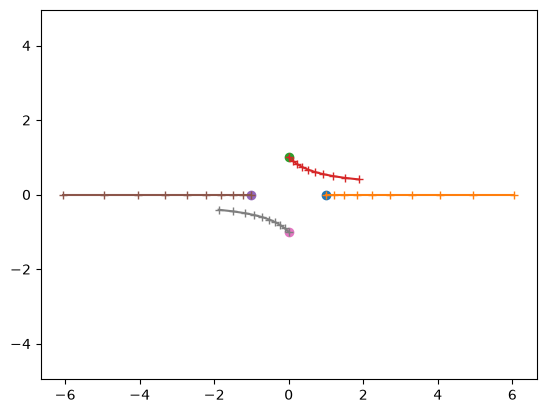

In [44]:
A = np.array([[2, 1], [0, -1]]) 
linear2D(A, t=np.arange(0, 1, 0.1))

3) Real eigenvalues $0 > \lambda_1 > \lambda_2$

EigResult(eigenvalues=array([-2.61803399+0.j, -0.38196601+0.j]), eigenvectors=array([[-0.85065081+0.j, -0.52573111+0.j],
       [ 0.52573111+0.j, -0.85065081+0.j]]))

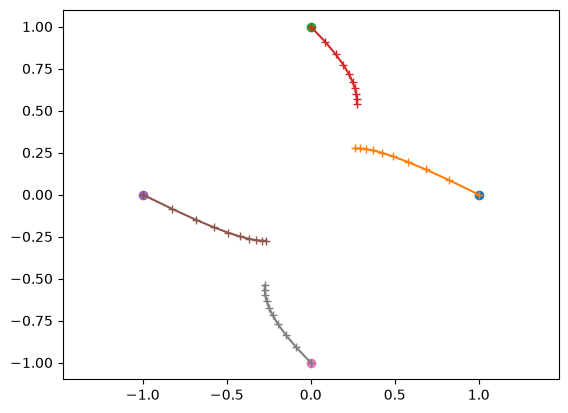

In [ ]:
A = np.array([[-2, 1], [1, -1]]) 
linear2D(A, t=np.arange(0, 1, 0.1))

4) Complex eigenvalues $\lambda_1=a+ib$ and $\lambda_2=a-ib$ with $a>0$

EigResult(eigenvalues=array([1.5+1.6583124j, 1.5-1.6583124j]), eigenvectors=array([[ 0.8660254 +0.j        ,  0.8660254 -0.j        ],
       [-0.14433757+0.47871355j, -0.14433757-0.47871355j]]))

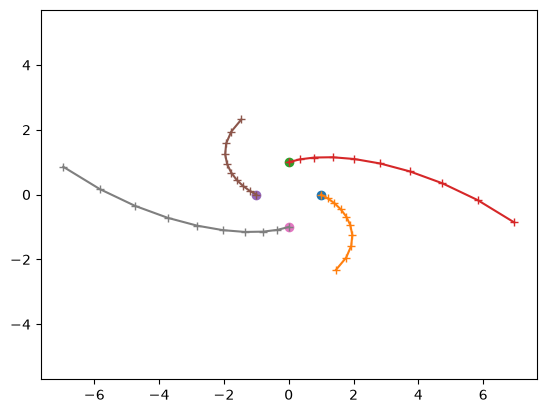

In [16]:
A = np.array([[2, 3], [-1, 1]]) 
linear2D(A, t=np.arange(0, 1, 0.1))

5) Complex eigenvalues $\lambda_1=a+ib$ and $\lambda_2=a-ib$ with $a<0$

EigResult(eigenvalues=array([-0.5+0.8660254j, -0.5-0.8660254j]), eigenvectors=array([[ 0.8660254+0.j  ,  0.8660254-0.j  ],
       [-0.4330127-0.25j, -0.4330127+0.25j]]))

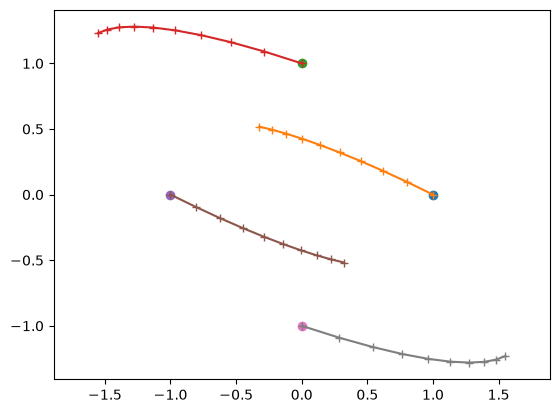

In [18]:
A = np.array([[-2, -3], [1, 1]]) 
linear2D(A, t=np.arange(0, 1, 0.1))

c.f. For a 2 by 2 matrix

$$ A = \pmatrix{a & b \\ c & d}, $$

we can analytically derive the eivenvalues from

$$ \det (A - \lambda I) = (a-\lambda)(d-\lambda) - bc = 0 $$

as

$$ \lambda = \frac{a+d}{2} \pm \sqrt{\frac{(a-d)^2}{4}+ bc}. $$

## 2. Nonlinear ODEs
1) Implement a nonlinear system, such as a pendulum with friction $\mu$:

$$ \frac{d\theta}{dt} = \omega $$

$$ ml^2 \frac{d\omega}{dt} = - \mu \omega - mgl \sin \theta $$

In [20]:
def pendulum(y, t, m=1, l=1, mu=1, g=9.8):
    """pendulum dynamics
    m:mass, l:length, mu:damping, g:gravity"""
    th, om = y
    dth = om
    dom = -(mu*om + m*g*l*np.sin(th)) / (m*l**2)
    return [dth, dom]

2) Run a simulation by `odeint()` and show the trajectory as (t, y(t))

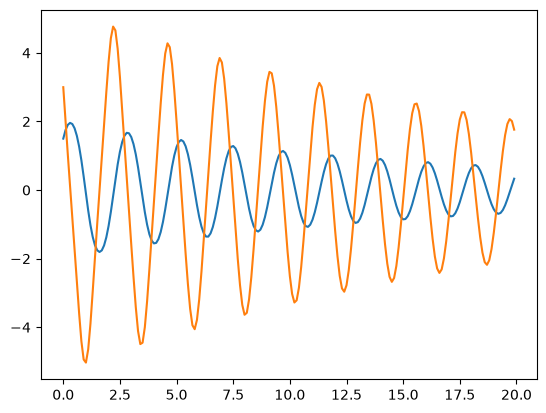

In [80]:
t = np.arange(0, 20, 0.1)
y0 = [1.5, 3] 
y = odeint(pendulum, y0, t, (1, 1, 0.1, 9.8))
plt.plot(t, y[:,0], label='theta (rad)')
plt.plot(t, y[:,1], label='omega (rad/s)')

3) Show the trajectory in the 2D state space $(\theta, \omega)$

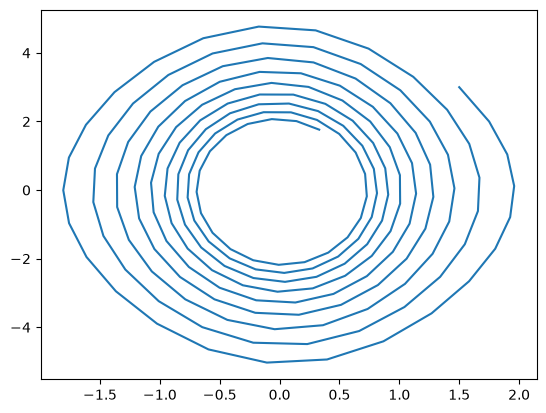

In [78]:
plt.plot(y[:,0], y[:,1])

Option) Implement a nonlinear system with time-dependent input, such as a forced pendulum:

$$ \frac{d\theta}{dt} = \omega $$

$$ ml^2 \frac{d\omega}{dt} = - \mu \omega - mgl \sin\theta + a\sin bt$$

and see how the behavior changes with the input.

In [27]:
def forced_pendulum(y, t, m=1, l=1, mu=1, g=9.8, a=1, b=1):
    """forced pendulum dynamics
    m:mass, l:length, mu:damping, g:gravity, a:amplitude, w:frequency"""
    th, om = y
    dth = om
    dom = -(mu*om + m*g*l*np.sin(th)) / (m*l**2) + a*np.cos(b*t)
    return [dth, dom]

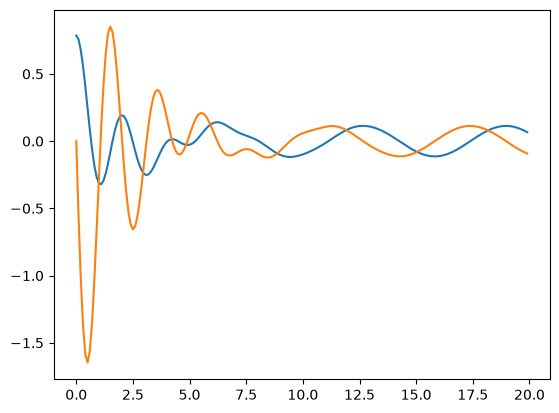

In [30]:
t = np.arange(0, 20, 0.1)
y0 = [np.pi/4, 0]
y = odeint(forced_pendulum, y0, t)
plt.plot(t, y[:,0], label='theta (rad)')
plt.plot(t, y[:,1], label='omega (rad/s)')

## 3. Bifurcation
FitzHugh-Nagumo model is an extension of Van der Pol model to approximate spiking behaviors of neurons.

$$ \frac{dv}{dt} = v - \frac{v^3}{3} - w + I $$

$$ \frac{dw}{dt} = \phi (v + a - bw) $$

1) Implement a function and see how the behaviors at different input current $I$.

In [31]:
def fhn(y, t, I=0, a=0.7, b=0.8, phi=0.08):
    """FitzHugh-Nagumo model"""
    v, w = y
    dv = v - v**3/3 - w + I
    dw = phi*(v + a - b*w)
    return [dv, dw]

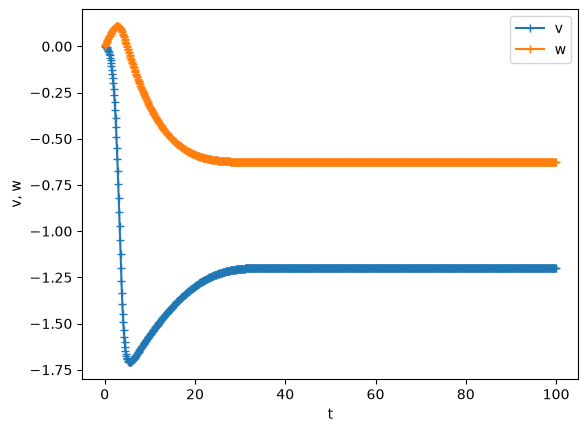

In [101]:
y0 = np.array([0, 0])
t = np.arange(0, 100, 0.1)
y = odeint(fhn, y0, t)
plt.plot(t, y, '+-')
plt.xlabel('t'); plt.ylabel('v, w');
plt.legend(['v', 'w'])

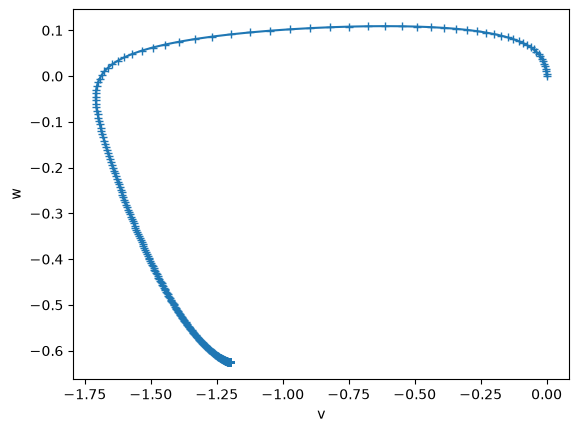

In [102]:
plt.plot(y[:,0], y[:,1], '+-')  # phase plot
plt.xlabel('v'); plt.ylabel('w');

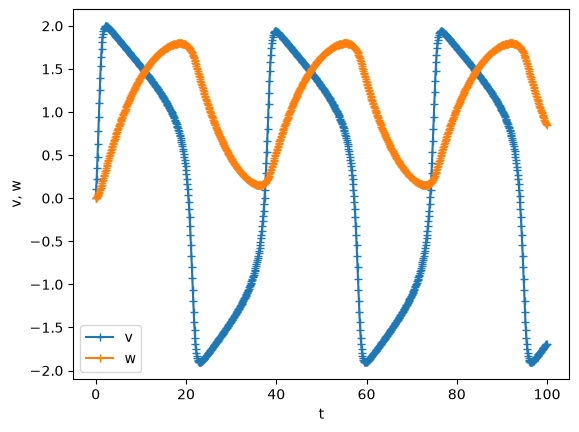

In [99]:
y0 = np.array([0, 0])
t = np.arange(0, 100, 0.1)
I = 1
y = odeint(fhn, y0, t, args=(I, 0.7, 0.8, 0.08))
plt.plot(t, y, '+-')
plt.xlabel('t'); plt.ylabel('v, w');
plt.legend(['v', 'w'])

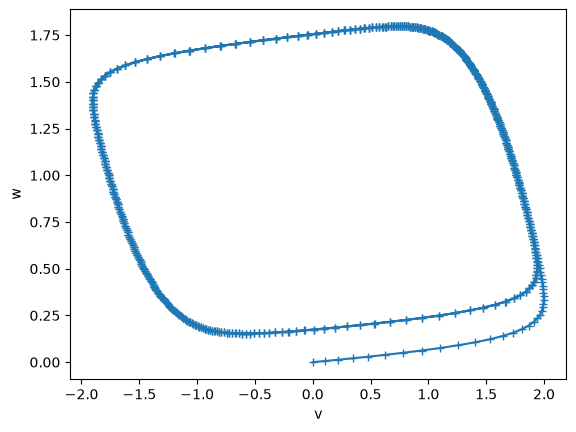

In [100]:
plt.plot(y[:,0], y[:,1], '+-')
plt.xlabel('v'); plt.ylabel('w');

2. Draw the nullclines $\frac{dv}{dt} = 0$ and $\frac{dw}{dt} = 0$, and overlay with the solution trajectories.

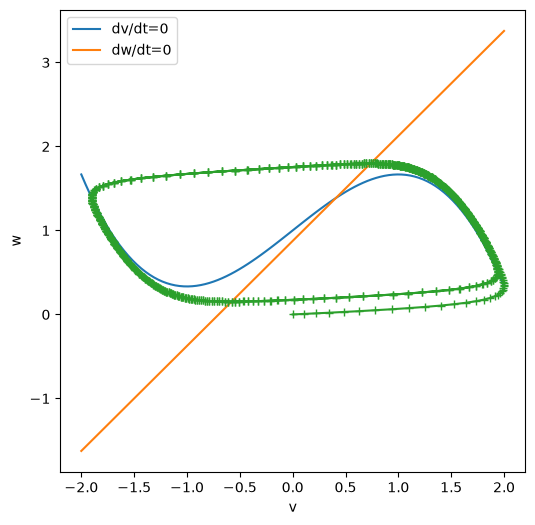

In [105]:
def nullcline_fhn(I=0, a=0.7, b=0.8, phi=0.08):
    """nullclines of FitzHugh-Nagumo model"""
    v = np.linspace(-2, 2, 100)
    w1 = v - v**3/3 + I
    w2 = (v + a)/b
    plt.plot(v, w1, label='dv/dt=0')
    plt.plot(v, w2, label='dw/dt=0')
    plt.xlabel('v')
    plt.ylabel('w')
    plt.legend()

plt.figure(figsize=(6,6))
I = 1
nullcline_fhn(I=I)
y0 = np.array([0, 0])
t = np.arange(0, 100, 0.1)
y = odeint(fhn, y0, t, args=(I, 0.7, 0.8, 0.08))
plt.plot(y[:,0], y[:,1], '+-')

3) Draw a *bifurcation diagram* showing the max-min of $v$ for different values of $I$.

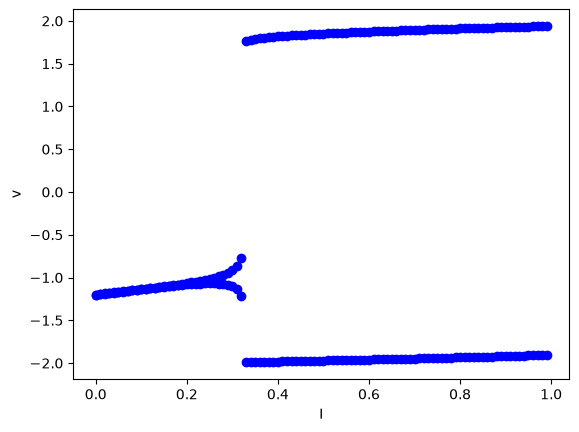

In [95]:
t = np.arange(0, 100, 0.1)
for I in np.arange(0, 1, 0.01):
    y = odeint(fhn, y0, t, args=(I,))  # change I
    plt.scatter(I, min(y[500:,0]), color='b')
    plt.scatter(I, max(y[500:,0]), color='b')
plt.xlabel('I'); plt.ylabel('v');